# Optional project diagnostics

This notebook checks the runtime, VOC data, contracts and previews.

In [1]:
%pip install "rich-click>=1.8,<2" "pytest>=8,<10" "pydantic-settings>=2,<3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pydantic-settings]pydantic-settings]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path

project_dir = Path("/kaggle/input/datasets/denysmykhailov/alseg-source/source")
sys.path.insert(0, str(project_dir))
sys.path.insert(0, str(project_dir / "tests"))
from alseg.config import load_config

config_path = project_dir / "configs" / "base.toml"
setup_script = project_dir / "script" / "setup_project.py"
tests_dir = project_dir / "tests"
project_version = load_config(project_dir / "pyproject.toml")["project"]["version"]

In [3]:
%run "$setup_script" --config "$config_path" --inspect-data

{
  "python": "3.13.18",
  "torch": "2.11.0+cpu",
  "cuda_available": false,
  "cuda_version": null,
  "gpu_count": 0,
  "dataset_root": "/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset",
  "data_checked": true,
  "voc_root": "/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val",
  "split_sizes": {
    "train": 1464,
    "val": 1449
  },
  "samples": {
    "train": {
      "stem": "2007_000032",
      "image_shape": [
        3,
        281,
        500
      ],
      "mask_shape": [
        281,
        500
      ],
      "class_ids": [
        0,
        1,
        15,
        255
      ],
      "void_pixels": 5355
    },
    "val": {
      "stem": "2007_000033",
      "image_shape": [
        3,
        366,
        500
      ],
      "mask_shape": [
        366,
        500
      ],
      "class_ids": [
        0,
        1,
        255
      ],
      "void_pixels": 8195
    }
  }
}


In [4]:
%run -m pytest -- -q -o cache_dir=/kaggle/working/alseg/pytest-cache "$tests_dir"

.

Usage: main [OPTIONS]

Report the runtime and optionally check the VOC segmentation mount.

╭─ Options ───────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ --config            FILE  Experiment configuration TOML. [default:                                              │
│                           /kaggle/input/datasets/denysmykhailov/alseg-source/source/configs/base.toml]          │
│ --check-data              Validate official train/val files.                                                    │
│ --inspect-data            Also decode the first train/val RGB and mask pairs; implies --check-data.             │
│ --help          -h        Show this message and exit.                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

..s.................................................................... [ 67%]
..................................                                       [100%]
=============================== warnings summary ===============================
tests/test_cli.py: 7 warnings
tests/test_config.py: 6 warnings
tests/test_contracts.py: 49 warnings
tests/test_data.py: 11 warnings
tests/test_encoder.py: 8 warnings
tests/test_environment.py: 4 warnings
tests/test_metrics.py: 6 warnings
tests/test_publish_source.py: 12 warnings
tests/test_setup.py: 6 warnings
  /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
    return datetime.utcnow().replace(tzinfo=utc)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
105 passed, 3 skipped, 109 warnings in 24.42s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
from synthetic import make_fixture

from alseg.core.selection import validate_selection

for dimension in (2, 5):
    fixture = make_fixture(dimension)
    validate_selection(fixture.request, fixture.expected_top_uncertainty)
    print("Embedding shape:", tuple(fixture.request.embeddings.shape))
    print(
        "Expected top-uncertainty IDs (tie-break by ID):",
        fixture.expected_top_uncertainty,
    )

Embedding shape: (6, 2)
Expected top-uncertainty IDs (tie-break by ID): [1, 3]
Embedding shape: (6, 5)
Expected top-uncertainty IDs (tie-break by ID): [1, 3]


In [6]:
import importlib.metadata
import json
import platform

import torch

setup_dir = Path("/kaggle/working/alseg/setup")
setup_dir.mkdir(parents=True, exist_ok=True)
environment = {
    "project_version": project_version,
    "source_dir": str(project_dir),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_names": [
        torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())
    ],
}
(setup_dir / "environment.json").write_text(json.dumps(environment, indent=2) + "\n")
packages = sorted(
    {
        f"{dist.metadata['Name']}=={dist.version}"
        for dist in importlib.metadata.distributions()
        if dist.metadata["Name"]
    }
)
(setup_dir / "requirements-kaggle.txt").write_text("\n".join(packages) + "\n")
print(json.dumps(environment, indent=2))
print("Environment snapshot:", setup_dir)

{
  "project_version": "0.6.3",
  "source_dir": "/kaggle/input/datasets/denysmykhailov/alseg-source/source",
  "python": "3.13.18",
  "torch": "2.11.0+cpu",
  "cuda_available": false,
  "cuda_version": null,
  "gpu_names": []
}
Environment snapshot: /kaggle/working/alseg/setup


Train ID 0: 2007_000032 classes: [0, 1, 15, 255]
RGB | class mask (void=magenta) | overlay


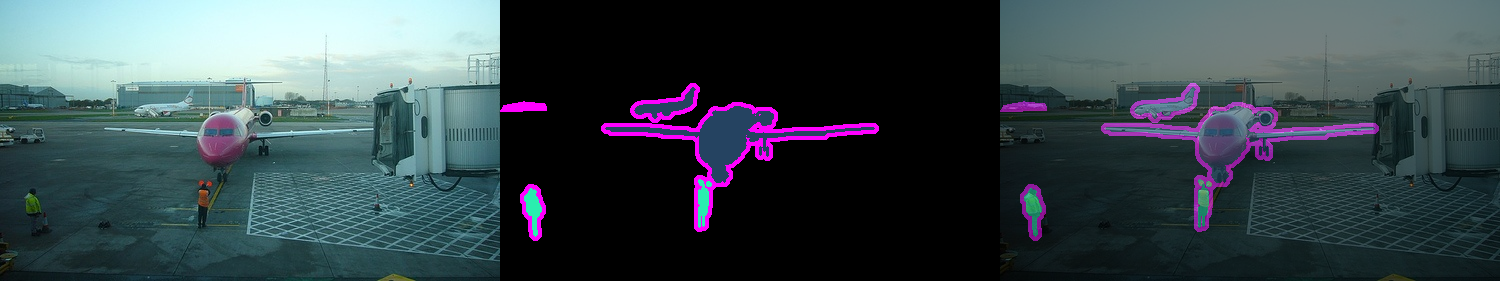

Val ID 0: 2007_000033 classes: [0, 1, 255]
Preview query audit: /kaggle/working/alseg/previews/79a6e202686548c082892a63f26bffdd/oracle_queries.jsonl


In [7]:
import uuid

import numpy as np
from IPython.display import display
from PIL import Image

from alseg.adapters.voc import VocEvaluation, VocImages, VocOracle
from alseg.data.voc import find_voc_root, load_manifest

data_config = load_config(config_path)["data"]
explicit_root = data_config["voc_root"]
voc_root = (
    Path(explicit_root)
    if explicit_root
    else find_voc_root(Path(data_config["dataset_root"]))
)
manifest = load_manifest(voc_root)
pool = VocImages(voc_root, manifest)
evaluation = VocEvaluation(voc_root, manifest)
# This diagnostic query is a separate preview run, never part of benchmark L.
preview_dir = Path("/kaggle/working/alseg/previews") / uuid.uuid4().hex
oracle = VocOracle(voc_root, manifest, preview_dir / "oracle_queries.jsonl")
image = pool.get_image(0)
mask = oracle.query([0])[0]
colors = np.array(
    [(i * 37 % 256, i * 67 % 256, i * 97 % 256) for i in range(256)], dtype=np.uint8
)
colors[255] = [255, 0, 255]  # Void, ignored during training/evaluation.
rgb = Image.fromarray(image.permute(1, 2, 0).numpy())
colored_mask = Image.fromarray(colors[mask.numpy()])
print("Train ID 0:", manifest.pool_ids[0], "classes:", mask.unique().tolist())
print("RGB | class mask (void=magenta) | overlay")
preview = Image.new("RGB", (rgb.width * 3, rgb.height))
for index, panel in enumerate((rgb, colored_mask, Image.blend(rgb, colored_mask, 0.5))):
    preview.paste(panel, (index * rgb.width, 0))
display(preview)
print(
    "Val ID 0:",
    manifest.val_ids[0],
    "classes:",
    evaluation.get_mask(0).unique().tolist(),
)
print("Preview query audit:", preview_dir / "oracle_queries.jsonl")